# Classificação de Espécies de Corujas com Redes Neurais

## 1. Introdução

A distinção visual entre aves exige a análise de traços morfológicos detalhados, como texturas da plumagem, proporções do bico e padrões faciais. Este projeto aplica Visão Computacional à identificação automatizada de 20 espécies de corujas a partir de um repositório público de imagens.

A tarefa é uma **classificação multiclasse**. Para melhorar a capacidade de extração de características sem treinar uma rede do zero, utilizamos **transfer learning com MobileNetV2**, pré-treinada na ImageNet, seguida de ajuste fino (*fine-tuning*). O experimento também considera o forte desbalanceamento da base e reserva um conjunto de teste independente para a avaliação final.

**Objetivos do projeto:** melhorar a eficácia preditiva, avaliar o desempenho geral e por espécie, identificar as principais confusões e discutir a viabilidade de uso em monitoramento não intrusivo da fauna.

Para reproduzir o experimento no Colab, selecione um ambiente com GPU e execute as células sequencialmente (**Ambiente de execução > Executar tudo**). Na primeira execução, os pesos da ImageNet serão baixados automaticamente. As saídas foram limpas porque a arquitetura, a divisão dos dados e a avaliação foram alteradas; os textos de discussão não pressupõem resultados ainda não executados.

## 2. Bibliotecas e reprodutibilidade

Utilizamos `NumPy` e `Pandas` para manipulação dos dados, `Matplotlib` para visualização, `Scikit-learn` para divisão estratificada, ponderação das classes e métricas, e `TensorFlow/Keras` para o processamento das imagens e a construção da rede. O `gdown` realiza o download da base.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn tensorflow gdown

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import callbacks, layers, models

SEMENTE = 42
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

Python: 3.13.16
NumPy: 2.4.6 | Pandas: 2.2.3
Scikit-learn: 1.6.1
TensorFlow: 2.21.0
Matplotlib: 3.10.0
GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Base de dados

A base contém imagens de 20 espécies organizadas em diretórios, nos quais o nome de cada subpasta representa o rótulo da espécie. A célula seguinte baixa e extrai o arquivo em `/content/imgs`. Em seguida, contamos somente arquivos com extensões de imagem compatíveis e verificamos a distribuição das classes.

O download e a extração são feitos apenas no armazenamento temporário da sessão do Colab. Se o ambiente for reiniciado, será necessário executar esta etapa novamente.

In [2]:
!gdown --id 1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is -O imgs.zip
!unzip -q -o imgs.zip -d /content/
!rm -f imgs.zip

print("Download e descompactação concluídos com sucesso!")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is
From (redirected): https://drive.google.com/uc?id=1fq87mnV4pG1PSV_qwWM3-IXlkWL4O6is&confirm=t&uuid=4048d506-bffd-4508-8ccf-746ca3c970c8
To: /content/imgs.zip
100% 985M/985M [00:13<00:00, 75.3MB/s]
Download e descompactação concluídos com sucesso!


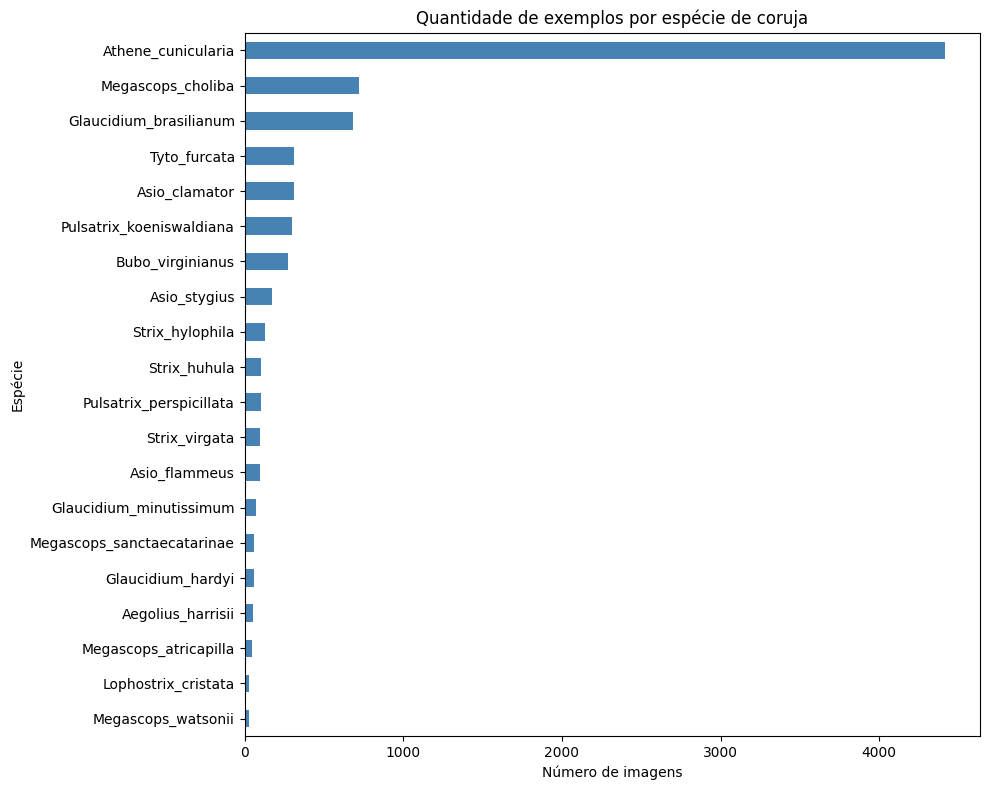

Total de classes (espécies): 20
Total de imagens na base: 8067


In [3]:
data_dir = Path("/content/imgs")
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

if not data_dir.is_dir():
    raise FileNotFoundError(
        f"Diretório não encontrado: {data_dir}. Execute a célula de download primeiro."
    )

nomes_das_classes = sorted(
    pasta.name for pasta in data_dir.iterdir() if pasta.is_dir()
)
contagem = {
    classe: sum(
        caminho.is_file() and caminho.suffix.lower() in EXTENSOES_IMAGEM
        for caminho in (data_dir / classe).iterdir()
    )
    for classe in nomes_das_classes
}

contagem_serie = pd.Series(contagem, dtype="int64").sort_values()
contagem_serie.plot.barh(figsize=(10, 8), color="steelblue")
plt.title("Quantidade de exemplos por espécie de coruja")
plt.xlabel("Número de imagens")
plt.ylabel("Espécie")
plt.tight_layout()
plt.show()

print("Total de classes (espécies):", len(contagem_serie))
print("Total de imagens na base:", int(contagem_serie.sum()))

In [4]:
print("Quantidade exata de imagens por espécie:")
print("-" * 50)
for especie, quantidade in contagem_serie.items():
    print(f"{especie}: {quantidade} imagens")

classe_majoritaria = contagem_serie.idxmax()
participacao_majoritaria = contagem_serie.max() / contagem_serie.sum()
print("-" * 50)
print(f"Total geral: {contagem_serie.sum()} imagens")
print(
    f"Classe majoritária: {classe_majoritaria} "
    f"({participacao_majoritaria:.1%} da base)"
)

Quantidade exata de imagens por espécie:
--------------------------------------------------
Megascops_watsonii: 26 imagens
Lophostrix_cristata: 27 imagens
Megascops_atricapilla: 44 imagens
Aegolius_harrisii: 55 imagens
Glaucidium_hardyi: 57 imagens
Megascops_sanctaecatarinae: 58 imagens
Glaucidium_minutissimum: 74 imagens
Asio_flammeus: 96 imagens
Strix_virgata: 96 imagens
Pulsatrix_perspicillata: 105 imagens
Strix_huhula: 106 imagens
Strix_hylophila: 131 imagens
Asio_stygius: 175 imagens
Bubo_virginianus: 271 imagens
Pulsatrix_koeniswaldiana: 300 imagens
Asio_clamator: 310 imagens
Tyto_furcata: 312 imagens
Glaucidium_brasilianum: 686 imagens
Megascops_choliba: 723 imagens
Athene_cunicularia: 4415 imagens
--------------------------------------------------
Total geral: 8067 imagens
Classe majoritária: Athene_cunicularia (54.7% da base)


**Análise da distribuição dos dados:**

A contagem confirma um desbalanceamento significativo. Uma única espécie representa mais da metade da base, enquanto várias classes têm poucas dezenas de amostras. Por isso, além da acurácia global, avaliaremos **acurácia balanceada, precisão, revocação e F1 macro**. As classes também terão pesos inversamente relacionados às suas frequências durante o treinamento, reduzindo a vantagem da classe majoritária na função de perda.

## 4. Metodologia e preparação

### 4.1. Divisão estratificada e pipeline de dados

Os arquivos são separados em **70% para treino, 15% para validação e 15% para teste**, preservando aproximadamente a proporção de cada espécie nos três conjuntos. O teste não participa do treinamento, da seleção de épocas nem da restauração dos melhores pesos; ele é usado uma única vez na avaliação final.

A semente `42` torna a divisão reprodutível. As imagens são decodificadas com três canais e redimensionadas para 224×224 pixels. O treino é embaralhado, enquanto validação e teste mantêm uma ordem fixa. Usamos lotes de 32 e `prefetch`, mas **não usamos `cache()`**, evitando armazenar toda a base decodificada na memória RAM.

In [5]:
tamanho_imagem = (224, 224)
tamanho_lote = 32
num_classes = len(nomes_das_classes)

caminhos = []
rotulos = []
for indice, classe in enumerate(nomes_das_classes):
    arquivos = sorted(
        caminho
        for caminho in (data_dir / classe).iterdir()
        if caminho.is_file() and caminho.suffix.lower() in EXTENSOES_IMAGEM
    )
    caminhos.extend(str(caminho) for caminho in arquivos)
    rotulos.extend([indice] * len(arquivos))

caminhos = np.asarray(caminhos)
rotulos = np.asarray(rotulos, dtype=np.int32)

# Primeiro separamos 30% temporários; depois os dividimos igualmente.
caminhos_treino, caminhos_temp, rotulos_treino, rotulos_temp = train_test_split(
    caminhos,
    rotulos,
    test_size=0.30,
    random_state=SEMENTE,
    stratify=rotulos,
)
caminhos_validacao, caminhos_teste, rotulos_validacao, rotulos_teste = train_test_split(
    caminhos_temp,
    rotulos_temp,
    test_size=0.50,
    random_state=SEMENTE,
    stratify=rotulos_temp,
)

AUTOTUNE = tf.data.AUTOTUNE


def carregar_imagem(caminho, rotulo):
    bytes_imagem = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(
        bytes_imagem, channels=3, expand_animations=False
    )
    imagem = tf.image.resize(imagem, tamanho_imagem)
    imagem.set_shape((*tamanho_imagem, 3))
    return imagem, rotulo


def criar_dataset(caminhos_conjunto, rotulos_conjunto, treinamento=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (caminhos_conjunto, rotulos_conjunto)
    )
    dataset = dataset.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    if treinamento:
        dataset = dataset.shuffle(
            buffer_size=min(len(caminhos_conjunto), 2048),
            seed=SEMENTE,
            reshuffle_each_iteration=True,
        )
    return dataset.batch(tamanho_lote).prefetch(AUTOTUNE)


dataset_treino = criar_dataset(caminhos_treino, rotulos_treino, treinamento=True)
dataset_validacao = criar_dataset(caminhos_validacao, rotulos_validacao)
dataset_teste = criar_dataset(caminhos_teste, rotulos_teste)

print(f"Treino:    {len(caminhos_treino)} imagens ({len(caminhos_treino)/len(caminhos):.1%})")
print(f"Validação: {len(caminhos_validacao)} imagens ({len(caminhos_validacao)/len(caminhos):.1%})")
print(f"Teste:     {len(caminhos_teste)} imagens ({len(caminhos_teste)/len(caminhos):.1%})")
print(f"Classes:   {num_classes}")

# Pesos calculados exclusivamente com os rótulos de treino.
classes_indices = np.arange(num_classes)
pesos = compute_class_weight(
    class_weight="balanced",
    classes=classes_indices,
    y=rotulos_treino,
)
pesos_das_classes = dict(zip(classes_indices, pesos))
print("Peso da classe majoritária:", round(pesos_das_classes[int(np.bincount(rotulos_treino).argmax())], 3))

Treino:    5646 imagens (70.0%)
Validação: 1210 imagens (15.0%)
Teste:     1211 imagens (15.0%)
Classes:   20
Peso da classe majoritária: 0.091


### 4.2. Pré-processamento dos pixels

A MobileNetV2 espera valores de ponto flutuante no intervalo **[-1, 1]**, e não no intervalo [0, 1]. A função oficial `tf.keras.applications.mobilenet_v2.preprocess_input` é incorporada ao modelo, garantindo que treino, avaliação e futuras inferências usem exatamente o mesmo pré-processamento.

O aumento de dados também fica dentro do modelo, mas suas camadas aleatórias são ativadas somente durante o treinamento.

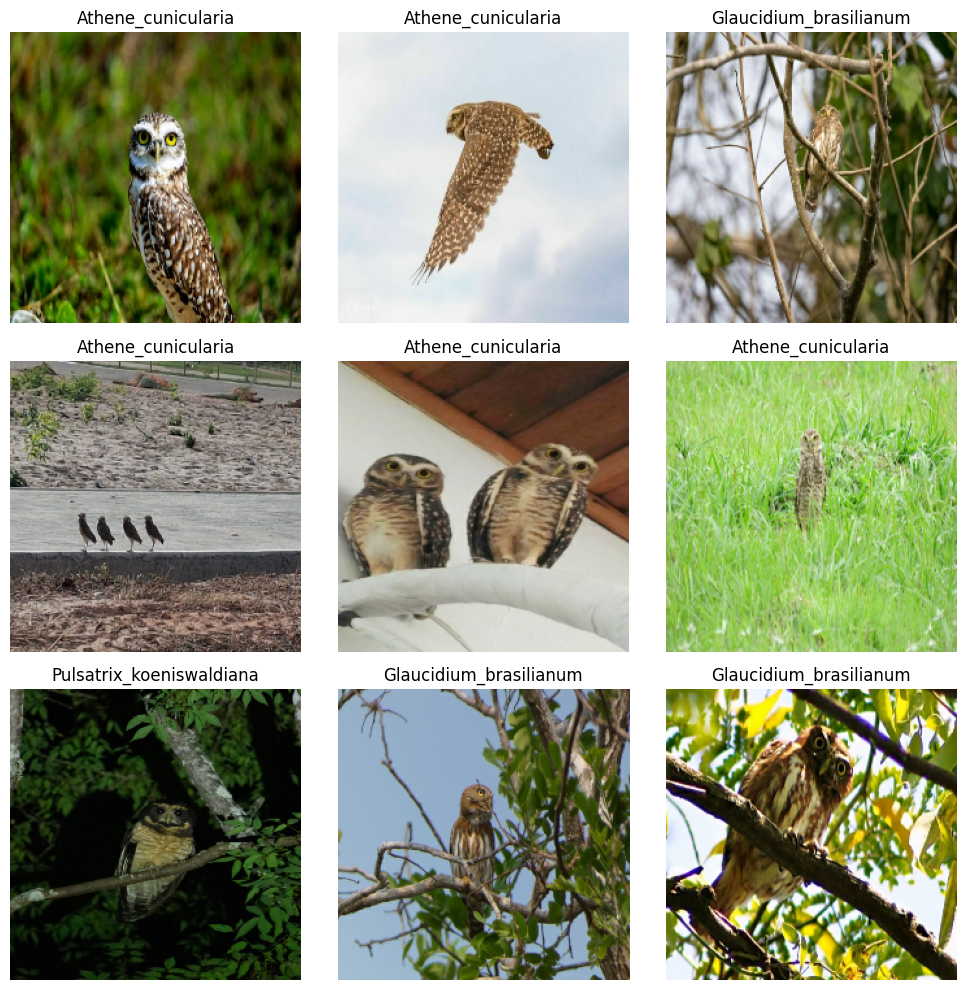

In [6]:
plt.figure(figsize=(10, 10))
for imagens, rotulos_lote in dataset_treino.take(1):
    for i in range(min(9, len(imagens))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype("uint8"))
        plt.title(nomes_das_classes[int(rotulos_lote[i])])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Transfer learning com MobileNetV2

Em vez de aprender todos os filtros a partir de apenas alguns milhares de imagens, aproveitamos uma **MobileNetV2 pré-treinada na ImageNet**. Sua cabeça original é substituída por `GlobalAveragePooling`, `Dropout` e uma camada `softmax` com 20 saídas. Além de reduzir o número de parâmetros treináveis, essa arquitetura é mais adequada a futuras aplicações em dispositivos de borda.

O treinamento tem duas etapas:

1. **Adaptação da cabeça:** a base convolucional permanece congelada por até 10 épocas. Aumento de dados, ponderação das classes e `EarlyStopping` são aplicados.
2. **Ajuste fino:** as últimas camadas convolucionais são liberadas com taxa de aprendizado baixa (`1e-5`) por até 15 épocas. As camadas de normalização em lote continuam congeladas para evitar atualizações instáveis com lotes pequenos.

Um `ModelCheckpoint` compartilhado guarda os pesos com a **menor perda de validação entre as duas etapas**. Ao final, esses pesos são restaurados antes de qualquer avaliação no teste.

In [7]:
entradas = layers.Input(shape=(*tamanho_imagem, 3), name="imagem")
x = layers.RandomFlip("horizontal")(entradas)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

base_modelo = tf.keras.applications.MobileNetV2(
    input_shape=(*tamanho_imagem, 3),
    include_top=False,
    weights="imagenet",
    pooling="avg",
)
base_modelo.trainable = False

# training=False mantém as estatísticas das BatchNorms estáveis nas duas etapas.
x = base_modelo(x, training=False)
x = layers.Dropout(0.3)(x)
saidas = layers.Dense(num_classes, activation="softmax", name="especie")(x)
modelo = models.Model(entradas, saidas, name="classificador_corujas")

caminho_melhores_pesos = "melhores_pesos_corujas.weights.h5"
salvar_melhores = callbacks.ModelCheckpoint(
    caminho_melhores_pesos,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    mode="min",
    verbose=1,
)

print("Etapa 1/2: adaptação da cabeça classificadora...")
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_inicial = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=10,
    class_weight=pesos_das_classes,
    callbacks=[
        salvar_melhores,
        callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
    ],
    verbose=2,
)

print("\nEtapa 2/2: ajuste fino das últimas camadas...")
base_modelo.trainable = True
for camada in base_modelo.layers[:100]:
    camada.trainable = False
for camada in base_modelo.layers:
    if isinstance(camada, layers.BatchNormalization):
        camada.trainable = False

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_ajuste = modelo.fit(
    dataset_treino,
    validation_data=dataset_validacao,
    epochs=15,
    class_weight=pesos_das_classes,
    callbacks=[
        salvar_melhores,
        callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
    ],
    verbose=2,
)

# Seleciona o melhor ponto global, inclusive se ele ocorreu na primeira etapa.
modelo.load_weights(caminho_melhores_pesos)
print("Melhores pesos de validação restaurados.")

history = {
    chave: history_inicial.history.get(chave, [])
    + history_ajuste.history.get(chave, [])
    for chave in ("accuracy", "val_accuracy", "loss", "val_loss")
}

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Etapa 1/2: adaptação da cabeça classificadora...
Epoch 1/10

Epoch 1: val_loss improved from None to 1.17628, saving model to melhores_pesos_corujas.weights.h5

Epoch 1: finished saving model to melhores_pesos_corujas.weights.h5
177/177 - 17s - 96ms/step - accuracy: 0.4008 - loss: 2.4139 - val_accuracy: 0.6694 - val_loss: 1.1763
Epoch 2/10

Epoch 2: val_loss improved from 1.17628 to 0.99423, saving model to melhores_pesos_corujas.weights.h5

Epoch 2: finished saving model to melhores_pesos_corujas.weights.h5
177/177 - 9s - 48ms/step - accuracy: 0.5813 - loss: 1.4351 - val_accuracy: 0.7008 - val_loss: 0.9942
Epoch 3/10

Epoch 3: val_loss improved from 0.99423 to 0.84951, saving model to melhores_pesos_corujas.weights.h5

Epoch 3: finished saving model to melhores_pesos_corujas.weights.h5
177/177 - 9s - 48ms/step - accuracy: 0.6190 - loss: 1.1898 - val_accuracy: 0.7413 - val_loss: 0.8495
Epoch 4/10

Epoch 4: val_loss did not improve from 0

## 6. Avaliação e análise dos resultados

As curvas de aprendizagem mostram treino e validação nas duas etapas. Uma linha tracejada marca o início do ajuste fino.

A avaliação final usa **somente o conjunto de teste**, que ficou isolado durante todo o treinamento. Além da acurácia, calculamos acurácia balanceada, precisão, revocação e F1 macro. O relatório por classe ajuda a verificar se as espécies minoritárias estão sendo reconhecidas. As probabilidades do `softmax` são convertidas em rótulos com `argmax` antes da matriz de confusão, que é normalizada por classe real para facilitar a comparação entre classes de tamanhos diferentes.

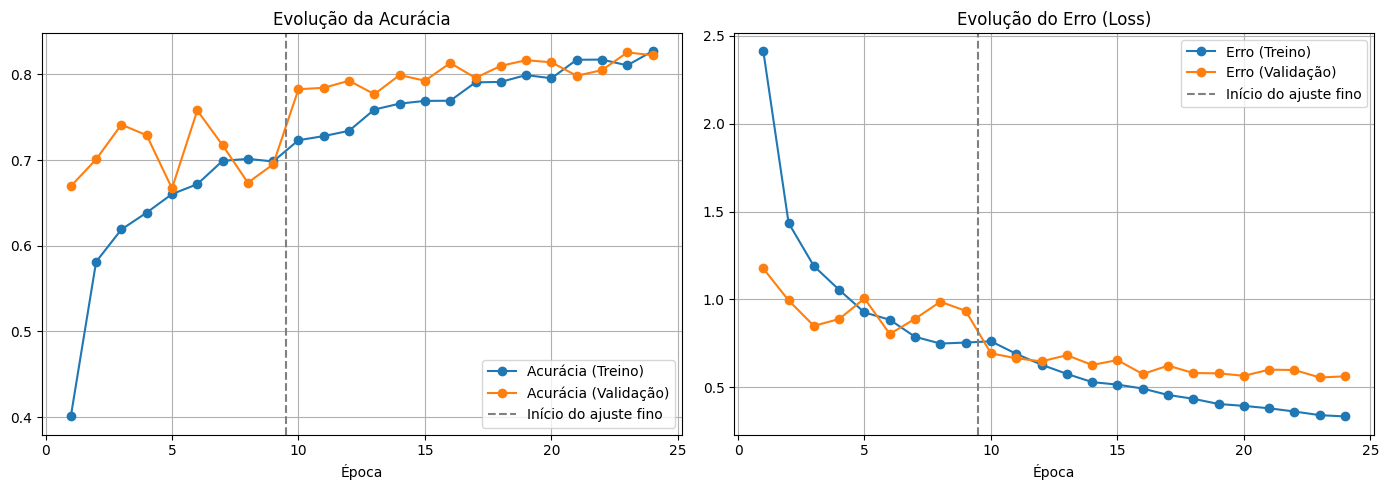

In [8]:
epocas = range(1, len(history["accuracy"]) + 1)
inicio_ajuste = len(history_inicial.history["loss"])

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epocas, history["accuracy"], label="Acurácia (Treino)", marker="o")
plt.plot(epocas, history["val_accuracy"], label="Acurácia (Validação)", marker="o")
plt.axvline(inicio_ajuste + 0.5, color="gray", linestyle="--", label="Início do ajuste fino")
plt.xlabel("Época")
plt.title("Evolução da Acurácia")
plt.legend(loc="lower right")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epocas, history["loss"], label="Erro (Treino)", marker="o")
plt.plot(epocas, history["val_loss"], label="Erro (Validação)", marker="o")
plt.axvline(inicio_ajuste + 0.5, color="gray", linestyle="--", label="Início do ajuste fino")
plt.xlabel("Época")
plt.title("Evolução do Erro (Loss)")
plt.legend(loc="upper right")
plt.grid(True)
plt.tight_layout()
plt.show()

Gerando previsões exclusivamente para o conjunto de teste...

Métricas da MobileNetV2 no teste:
  loss_teste: 0.5635
  acuracia: 0.8266
  acuracia_balanceada: 0.7043
  precisao_macro: 0.6651
  recall_macro: 0.7043
  f1_macro: 0.6628
  top3: 0.9538

Relatório por espécie:
                            precision    recall  f1-score   support

         Aegolius_harrisii      1.000     0.875     0.933         8
             Asio_clamator      0.683     0.872     0.766        47
             Asio_flammeus      0.310     0.643     0.419        14
              Asio_stygius      0.778     0.778     0.778        27
        Athene_cunicularia      0.976     0.902     0.937       663
          Bubo_virginianus      0.705     0.756     0.729        41
    Glaucidium_brasilianum      0.861     0.602     0.709       103
         Glaucidium_hardyi      0.185     0.625     0.286         8
   Glaucidium_minutissimum      0.192     0.455     0.270        11
       Lophostrix_cristata      1.000     0.750

,Classe,Suporte,Recall
12,Megascops_sanctaecatarinae,8,0.250
10,Megascops_atricapilla,6,0.333
8,Glaucidium_minutissimum,11,0.455
6,Glaucidium_brasilianum,103,0.602
7,Glaucidium_hardyi,8,0.625
2,Asio_flammeus,14,0.643
17,Strix_hylophila,20,0.700
18,Strix_virgata,14,0.714
13,Megascops_watsonii,4,0.750
15,Pulsatrix_perspicillata,16,0.750


Classes com recall zero: nenhuma
Classes com recall < 10%: nenhuma


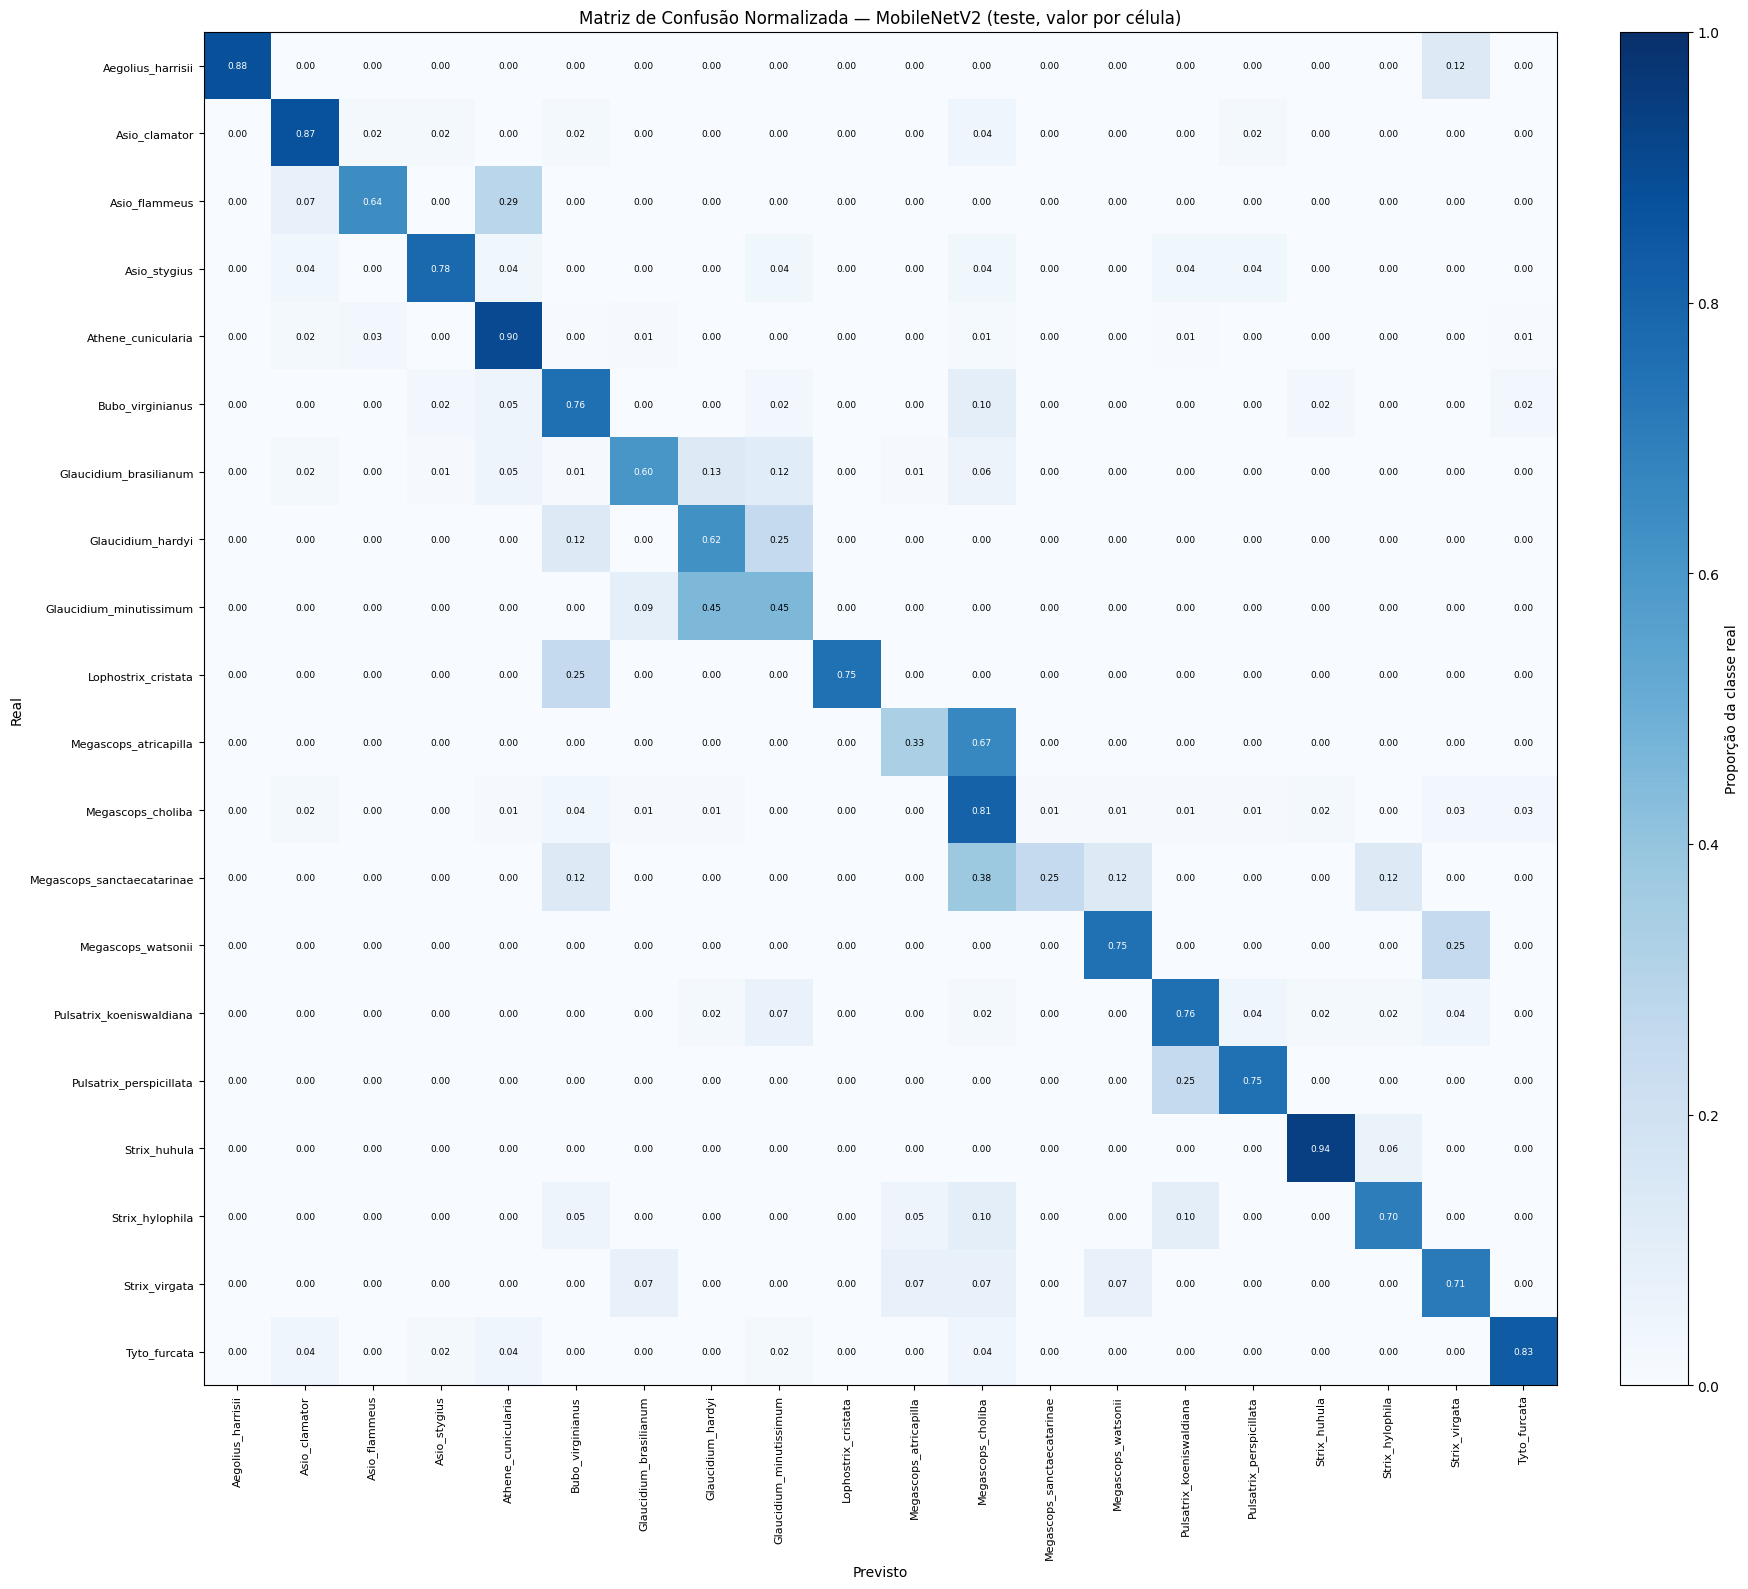

Parâmetros da MobileNetV2: 2,283,604
Tamanho aproximado dos pesos: 8.71 MB

Observação: esta avaliação usa o conjunto de teste do split 70/15/15.


,MobileNetV2 (teste)
loss_teste,5.635000e-01
acuracia,8.266000e-01
acuracia_balanceada,7.043000e-01
precisao_macro,6.651000e-01
recall_macro,7.043000e-01
f1_macro,6.628000e-01
top3,9.538000e-01
parametros,2.283604e+06
tamanho_mb,8.711300e+00


In [9]:
import numpy as np
import pandas as pd
from IPython.display import display

print("Gerando previsões exclusivamente para o conjunto de teste...")
perda_teste, acuracia_teste_keras = modelo.evaluate(dataset_teste, verbose=0)
y_probabilidades = modelo.predict(dataset_teste, verbose=0)
y_reais = np.asarray(rotulos_teste)
y_previstos = np.argmax(y_probabilidades, axis=1)

top3 = np.mean(
    np.any(
        np.argsort(y_probabilidades, axis=1)[:, -3:] == y_reais[:, None],
        axis=1,
    )
)

metricas_mobilenet = {
    'loss_teste': float(perda_teste),
    'acuracia': float(accuracy_score(y_reais, y_previstos)),
    'acuracia_balanceada': float(balanced_accuracy_score(y_reais, y_previstos)),
    'precisao_macro': float(precision_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'recall_macro': float(recall_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'f1_macro': float(f1_score(y_reais, y_previstos, average='macro', zero_division=0)),
    'top3': float(top3),
}

print("\nMétricas da MobileNetV2 no teste:")
for nome, valor in metricas_mobilenet.items():
    print(f"  {nome}: {valor:.4f}")

print("\nRelatório por espécie:")
print(classification_report(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    target_names=nomes_das_classes,
    digits=3,
    zero_division=0,
))

recall_classes = recall_score(
    y_reais, y_previstos, labels=np.arange(num_classes),
    average=None, zero_division=0
)
suporte = np.bincount(y_reais, minlength=num_classes)

tabela_recall = pd.DataFrame({
    'Classe': nomes_das_classes,
    'Suporte': suporte,
    'Recall': recall_classes,
}).sort_values('Recall')

display(tabela_recall.round(3))

sem_recall = tabela_recall.loc[tabela_recall['Recall'] == 0, 'Classe'].tolist()
baixo_recall = tabela_recall.loc[tabela_recall['Recall'] < 0.10, 'Classe'].tolist()
print("Classes com recall zero:", sem_recall if sem_recall else "nenhuma")
print("Classes com recall < 10%:", baixo_recall if baixo_recall else "nenhuma")

cm = confusion_matrix(
    y_reais,
    y_previstos,
    labels=np.arange(num_classes),
    normalize='true',
)

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(nomes_das_classes, rotation=90, fontsize=8)
ax.set_yticklabels(nomes_das_classes, fontsize=8)
ax.set_xlabel('Previsto')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusão Normalizada — MobileNetV2 (teste, valor por célula)')

for i in range(num_classes):
    for j in range(num_classes):
        valor = cm[i, j]
        ax.text(
            j, i, f'{valor:.2f}',
            ha='center', va='center', fontsize=6.5,
            color='white' if valor > 0.55 else 'black'
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Proporção da classe real')
plt.tight_layout()
plt.show()

parametros = modelo.count_params()
tamanho_mb = parametros * 4 / (1024 ** 2)
print(f"Parâmetros da MobileNetV2: {parametros:,}")
print(f"Tamanho aproximado dos pesos: {tamanho_mb:.2f} MB")
print("\nObservação: esta avaliação usa o conjunto de teste do split 70/15/15.")


resumo_metricas = pd.DataFrame([{
    **(metricas_mobilenet),
    'parametros': parametros,
    'tamanho_mb': tamanho_mb,
}]).T.rename(columns={0: 'MobileNetV2 (teste)'})
display(resumo_metricas.round(4))


## 7. Conclusão e aplicações práticas em Engenharia

Esta versão substitui a CNN treinada do zero por transfer learning e ajuste fino, abordagens mais apropriadas para uma base pequena e desbalanceada. Também separa validação e teste, pondera as classes pelo conjunto de treino, corrige a obtenção dos rótulos previstos e elimina o cache integral das imagens.

A conclusão quantitativa deve ser feita com os valores efetivamente impressos na seção anterior. A **acurácia de teste** mede o desempenho global, enquanto **F1 macro e acurácia balanceada** mostram se o resultado depende excessivamente das espécies frequentes. A matriz normalizada permite localizar as espécies com menor revocação e os pares mais confundidos. Como a divisão de dados mudou, os resultados desta versão e da anterior não são diretamente equivalentes; uma comparação rigorosa exigiria avaliar ambos os modelos no mesmo conjunto de teste.

Se as classes minoritárias ainda apresentarem baixo desempenho, os próximos passos são coletar mais amostras, revisar rótulos e duplicatas, testar amostragem balanceada e realizar busca controlada de hiperparâmetros usando apenas treino e validação. O conjunto de teste não deve ser usado para essas escolhas.

**Aplicações em sistemas reais**

Para uso prático, o modelo pode ser exportado, otimizado e quantizado para inferência em um dispositivo de borda compatível, como um computador embarcado com acelerador. Integrado a uma câmera e instalado em um invólucro resistente às intempéries, o sistema poderia apoiar o monitoramento da biodiversidade de forma não intrusiva. Antes da implantação, seria necessário validar o modelo com imagens do ambiente real, medir latência e consumo e avaliar cuidadosamente falsos positivos e falsos negativos.